# Semana 17 — Especialización: decisión sensorial bayesiana

**Objetivo:** derivar la regla de decisión óptima para una tarea de dos alternativas con
observaciones ruidosas, y comparar su precisión simulada con la teórica.

## Modelo

Un estímulo está a la izquierda ($L$, media $\mu_L = -1$) o a la derecha ($R$, $\mu_R = +1$), con
la misma probabilidad a priori. El observador recibe una medida ruidosa
$x \sim \mathcal{N}(\mu_s, \sigma^2)$. Por la regla de Bayes:

$$P(R \mid x) = \frac{p(x \mid R)\,P(R)}{p(x \mid R)\,P(R) + p(x \mid L)\,P(L)} = \frac{1}{1 + e^{-\ell(x)}}, \qquad
  \ell(x) = \log\frac{p(x\mid R)}{p(x\mid L)} = \frac{(x-\mu_L)^2 - (x-\mu_R)^2}{2\sigma^2}$$

Con priors y costos iguales, la decisión óptima es elegir $R$ si $P(R\mid x) > 0.5$, es decir, si
$x > 0$. Su precisión teórica es

$$P(\text{correcto}) = \Phi\!\left(\frac{\mu_R - \mu_L}{2\sigma}\right) = \Phi\!\left(\frac{d'}{2}\right)$$

donde $\Phi$ es la función de distribución normal estándar y $d' = (\mu_R - \mu_L)/\sigma$.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 17
MEAN_LEFT, MEAN_RIGHT = -1.0, 1.0
NOISE_SD = 1.2
TRIALS = 4000
rng = np.random.default_rng(17)


def posterior_right(observation: np.ndarray, noise_sd: float) -> np.ndarray:
    log_ratio = ((observation - MEAN_LEFT) ** 2 - (observation - MEAN_RIGHT) ** 2) / (2 * noise_sd**2)
    return 1.0 / (1.0 + np.exp(-log_ratio))


def normal_cdf(value: float) -> float:
    return 0.5 * (1.0 + math.erf(value / math.sqrt(2.0)))


def simulated_accuracy(noise_sd: float) -> float:
    truth_right = rng.random(TRIALS) < 0.5
    observation = rng.normal(np.where(truth_right, MEAN_RIGHT, MEAN_LEFT), noise_sd)
    choice_right = posterior_right(observation, noise_sd) > 0.5
    return float(np.mean(choice_right == truth_right))


observations = np.linspace(-4.0, 4.0, 400)
sample_left = rng.normal(MEAN_LEFT, NOISE_SD, 100)
sample_right = rng.normal(MEAN_RIGHT, NOISE_SD, 100)
noise_levels = np.array([0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0])
simulated = np.array([simulated_accuracy(sd) for sd in noise_levels])
theoretical = np.array([normal_cdf((MEAN_RIGHT - MEAN_LEFT) / (2 * sd)) for sd in noise_levels])

## Figura

Izquierda: posterior $P(R \mid x)$ y muestras de cada estímulo (σ = 1.2). Las muestras del lado
equivocado de $x = 0$ son los errores inevitables. Derecha: precisión simulada (4000 ensayos)
frente a la teórica $\Phi(d'/2)$ para varios niveles de ruido.

Saved: weeks/week_17_bayesian_decision/outputs/bayesian_decision.png
Saved: weeks/week_17_bayesian_decision/outputs/bayesian_decision.npz


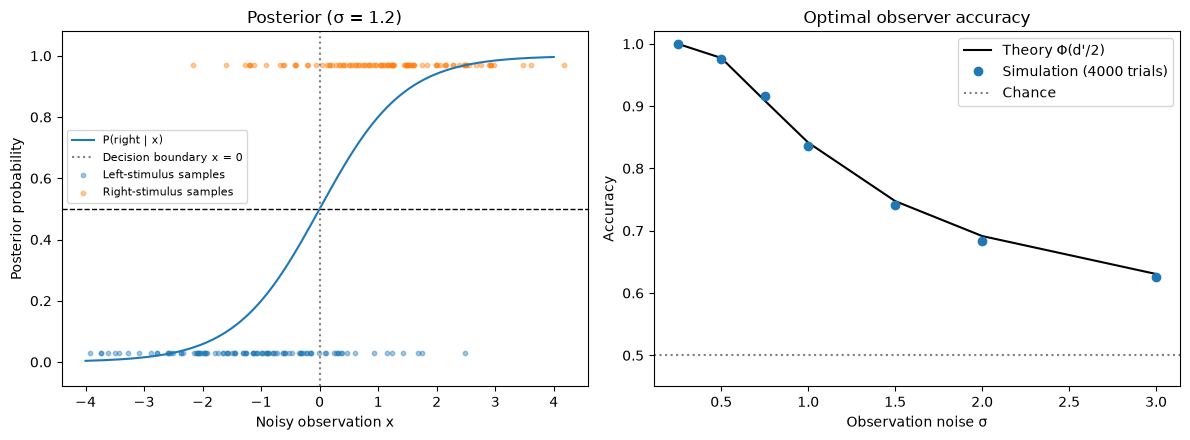

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(observations, posterior_right(observations, NOISE_SD), label="P(right | x)")
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].axvline(0.0, color="grey", linestyle=":", label="Decision boundary x = 0")
axes[0].scatter(sample_left, np.full(sample_left.size, 0.03), s=10, alpha=0.4, label="Left-stimulus samples")
axes[0].scatter(sample_right, np.full(sample_right.size, 0.97), s=10, alpha=0.4, label="Right-stimulus samples")
axes[0].set(xlabel="Noisy observation x", ylabel="Posterior probability", ylim=(-0.08, 1.08), title=f"Posterior (σ = {NOISE_SD})")
axes[0].legend(fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.62))
axes[1].plot(noise_levels, theoretical, "k-", label="Theory Φ(d'/2)")
axes[1].plot(noise_levels, simulated, "o", label=f"Simulation ({TRIALS} trials)")
axes[1].axhline(0.5, color="grey", linestyle=":", label="Chance")
axes[1].set(xlabel="Observation noise σ", ylabel="Accuracy", ylim=(0.45, 1.02), title="Optimal observer accuracy")
axes[1].legend()
save_figure(WEEK, figure, "bayesian_decision.png")
save_data(WEEK, "bayesian_decision.npz", observations=observations, posterior_right=posterior_right(observations, NOISE_SD),
          noise_levels=noise_levels, simulated_accuracy=simulated, theoretical_accuracy=theoretical)

## Validación

- La posterior vale 0.5 exactamente en la frontera $x = 0$ y es monótona creciente.
- La precisión simulada coincide con $\Phi(d'/2)$ dentro de 3 errores estándar binomiales.
- La precisión baja hacia el azar (0.5) al crecer el ruido.

In [3]:
posterior = posterior_right(observations, NOISE_SD)
assert abs(float(posterior_right(np.array([0.0]), NOISE_SD)[0]) - 0.5) < 1e-12
assert np.all(np.diff(posterior) > 0)
binomial_se = np.sqrt(theoretical * (1 - theoretical) / TRIALS)
assert np.all(np.abs(simulated - theoretical) < 3 * binomial_se + 1e-3), simulated - theoretical
assert np.all(np.diff(theoretical) < 0)
print("Accuracy simulated vs theory:", {f"sd={sd:g}": f"{s:.3f}/{t:.3f}" for sd, s, t in zip(noise_levels, simulated, theoretical)})

Accuracy simulated vs theory: {'sd=0.25': '1.000/1.000', 'sd=0.5': '0.976/0.977', 'sd=0.75': '0.917/0.909', 'sd=1': '0.837/0.841', 'sd=1.5': '0.742/0.748', 'sd=2': '0.683/0.691', 'sd=3': '0.625/0.631'}


## Interpretación y límites

- Ningún observador puede superar $\Phi(d'/2)$ con esta información: es un límite de desempeño.
- Si los priors o los costos no son iguales, la frontera se desplaza:
  $x^* = \frac{\sigma^2}{\mu_R - \mu_L}\log\frac{P(L)}{P(R)}$.
- Los sujetos reales suelen rendir por debajo del óptimo (ruido de decisión, sesgos, lapsos).

**Para tu entrega:** usa $P(R) = 0.7$, calcula la nueva frontera y verifica la precisión con simulación.